# Power iteration: paired intermediate probes

Four network layers, two normalization conditions (`111` and `000`), and eight
intermediate power-method targets per layer. The backbone still learns the leading
eigenvector. All implementation is in separate Python files with English comments.

Choose a GPU runtime. Upload the source archive, calibrate the targets, then run the
training cell. Results are stored in your Google Drive.


In [ ]:
from pathlib import Path
import json
import sys
import zipfile
import numpy as np
import torch
from google.colab import drive

# Upload source.zip through the Files panel before running this cell.
source_archive = Path('/content/source.zip')
source_dir = Path('/content/power_iteration_32d')
source_dir.mkdir(exist_ok=True)
with zipfile.ZipFile(source_archive) as archive:
    for name in archive.namelist():
        if not (source_dir / name).resolve().is_relative_to(source_dir.resolve()):
            raise ValueError('Archive contains an invalid path.')
    archive.extractall(source_dir)
sys.path.insert(0, str(source_dir))
print('Source folder:', source_dir)
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'not available')


Source folder: /content/power_iteration_32d
GPU: Tesla T4


In [ ]:
from datetime import datetime, timezone
from src.io import atomic_json
from experiments.run_study import run

drive.mount('/content/drive')

# Edit the run name here. Reuse it only to resume the same experiment.
run_name = 'paired_power_32d_' + datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S')
results_root = Path('/content/drive/MyDrive') / 'power_iteration' / 'runs'
run_dir = results_root / run_name
cache_dir = Path('/content/power_iteration_32d_cache')
config_path = source_dir / 'configs' / 'study.json'
cfg = json.loads(config_path.read_text())
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Results:', run_dir)
print('Candidate pairs:', len(cfg['seeds']))
print('Conditions:', cfg['masks'])
print('Validation error limit:', cfg['maximum_validation_error'])
print('Validation gap limit:', cfg['maximum_validation_gap'])


Mounted at /content/drive
Results: /content/drive/MyDrive/power_iteration/runs/paired_power_32d_20261125_221417
Candidate pairs: 32
Conditions: ['111', '000']
Validation error limit: 0.2
Validation gap limit: 0.025


## Calibrate the eight intermediate targets

This cell generates independent calibration data. It does not train a network or use
probe test data. Close powers are avoided using their measured directional separation.


Selected intermediate powers: [1, 2, 3, 4, 6, 8, 11, 16]
Selected powers: [1, 2, 3, 4, 6, 8, 11, 16]
Mean q16 error to the eigenvector: 0.22318056670366718


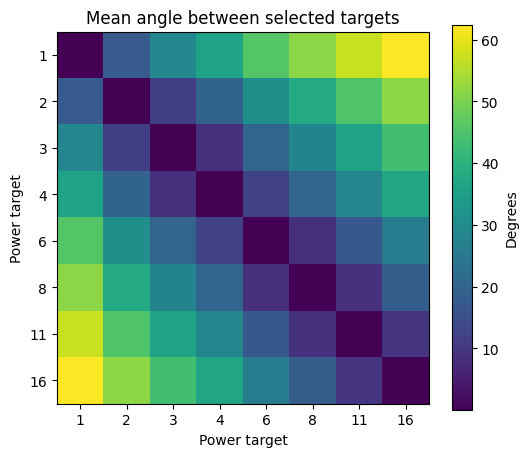

In [ ]:
selection = run(cfg, run_dir, cache_dir, device, phase='calibrate')
powers = selection['powers']
print('Selected powers:', powers)
print('Mean q16 error to the eigenvector:', selection['mean_error_to_eigenvector'][16])

import matplotlib.pyplot as plt
angles = np.asarray(selection['geometry']['mean_angle_degrees'])
fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(angles[np.ix_(powers, powers)], cmap='viridis')
ax.set_xticks(range(len(powers)), powers)
ax.set_yticks(range(len(powers)), powers)
ax.set(xlabel='Power target', ylabel='Power target', title='Mean angle between selected targets')
fig.colorbar(image, ax=ax, label='Degrees')
plt.show()


## Train the paired models and evaluate eligible pairs

Run this cell when you are ready to begin the Colab GPU job. Each arm stops at the
second consecutive passing validation checkpoint, up to 9,600 updates. Only eligible
pairs receive the primary bypass and intermediate-probe analysis. Failed and capped runs
remain in the records.


In [ ]:
if not torch.cuda.is_available():
    raise RuntimeError('Select a GPU runtime before starting the full study.')
torch.set_num_threads(1)
run(cfg, run_dir, cache_dir, device, phase='train')


Selected intermediate powers: [1, 2, 3, 4, 6, 8, 11, 16]
seed=101 mask=111 step=50 validation=0.966504
seed=101 mask=111 step=100 validation=0.961878
seed=101 mask=111 step=150 validation=0.922794
seed=101 mask=111 step=200 validation=0.869965
seed=101 mask=111 step=250 validation=0.804918
seed=101 mask=111 step=300 validation=0.763510
seed=101 mask=111 step=350 validation=0.717853
seed=101 mask=111 step=400 validation=0.645785
seed=101 mask=111 step=450 validation=0.644030
seed=101 mask=111 step=500 validation=0.618503
seed=101 mask=111 step=550 validation=0.557266
seed=101 mask=111 step=600 validation=0.550505
seed=101 mask=111 step=650 validation=0.514790
seed=101 mask=111 step=700 validation=0.460170
seed=101 mask=111 step=750 validation=0.477619
seed=101 mask=111 step=800 validation=0.460517
seed=101 mask=111 step=850 validation=0.430728
seed=101 mask=111 step=900 validation=0.434375
seed=101 mask=111 step=950 validation=0.414848
seed=101 mask=111 step=1000 validation=0.388787
see

KeyboardInterrupt: 

## Inspect saved results

Probe split seeds are averaged within each model. Independent training seeds are the
unit of comparison. Input layer 0 is a baseline in addition to network layers 1–4.


In [ ]:
import pandas as pd

for filename in ['complete.json', 'pairs.json']:
    path = run_dir / filename
    if path.exists():
        record = json.loads(path.read_text())
        display(pd.DataFrame(record) if isinstance(record, list) else record)
for filename in ['probe-summary.csv', 'bypass.csv']:
    path = run_dir / filename
    if path.exists():
        display(pd.read_csv(path, dtype={'mask': str}))


In [ ]:
import subprocess

# Check the saved models without updating any weights.
subprocess.run([sys.executable, '/content/audit_current_run.py',
                '--run', str(run_dir), '--source', str(source_dir),
                '--cache', str(cache_dir)], check=True)


CompletedProcess(args=['/usr/bin/python3', '/content/audit_current_run.py', '--run', '/content/drive/MyDrive/power_iteration/runs/paired_power_32d_20261125_221417', '--source', '/content/power_iteration_32d', '--cache', '/content/power_iteration_32d_cache'], returncode=0)

In [ ]:
audit = json.loads((run_dir / 'training-audit.json').read_text())
for row in audit:
    print(json.dumps(row))


{"seed": 101, "same_initialization": true, "same_batches": true, "arms": {"111": {"saved_validation_error": 0.2362180008475766, "train_error": 0.20438657570803634, "train_invalid_outputs": 0, "validation_error": 0.2362180008475766, "validation_invalid_outputs": 0, "layer_log10_peak_coordinates": [-0.22556534755772867, -0.26996265177544176, -0.22367520296321752, 1.7162187967774527], "validation_score_difference": 0.0}, "000": {"saved_validation_error": 0.6081677359008973, "train_error": 0.6103966392818105, "train_invalid_outputs": 0, "validation_error": 0.6081677359008973, "validation_invalid_outputs": 0, "layer_log10_peak_coordinates": [0.4181027500854816, 3.7053041875477994, 13.85757839557277, 43.574233865564935], "validation_score_difference": 0.0}}, "validation_gap": 0.37194973505332074}
{"seed": 102, "same_initialization": true, "same_batches": true, "arms": {"111": {"saved_validation_error": 0.23307525318868533, "train_error": 0.20506950623659237, "train_invalid_outputs": 0, "vali

In [ ]:
import shutil
import subprocess

# Preserve the interrupted recipe and its source code.
snapshot = run_dir / 'source'
if not snapshot.exists():
    shutil.copytree(source_dir, snapshot, ignore=shutil.ignore_patterns('__pycache__'))

# Run the revised recipe search in a separate process and directory.
pilot_source = Path('/content/power_iteration_matched')
pilot_source.mkdir(exist_ok=True)
with zipfile.ZipFile('/content/source_matched.zip') as archive:
    archive.extractall(pilot_source)
pilot_run = results_root / ('pilot_matched_32d_' + datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S'))
command = [sys.executable, '-m', 'experiments.pilot_training',
           '--output', str(pilot_run), '--cache', str(cache_dir)]
print('Pilot results:', pilot_run, flush=True)
process = subprocess.Popen(command, cwd=pilot_source, stdout=subprocess.PIPE,
                           stderr=subprocess.STDOUT, text=True, bufsize=1)
try:
    for line in process.stdout:
        print(line, end='', flush=True)
    returncode = process.wait()
except BaseException:
    process.terminate()
    process.wait()
    raise
if returncode:
    raise RuntimeError(f'Pilot exited with code {returncode}')


Pilot results: /content/drive/MyDrive/power_iteration/runs/pilot_matched_32d_20261125_232352
PILOT_START recipe=std003_lr0005 seed=9001
seed=9001 mask=111 step=200 validation=0.967812
seed=9001 mask=111 step=400 validation=0.967567
seed=9001 mask=111 step=600 validation=0.953548
seed=9001 mask=111 step=800 validation=0.784210
seed=9001 mask=111 step=1000 validation=0.631135
seed=9001 mask=111 step=1200 validation=0.525608
seed=9001 mask=111 step=1400 validation=0.460286
seed=9001 mask=111 step=1600 validation=0.398598
seed=9001 mask=111 step=1800 validation=0.377429
seed=9001 mask=111 step=2000 validation=0.352494
seed=9001 mask=111 step=2200 validation=0.333105
seed=9001 mask=111 step=2400 validation=0.321668
seed=9001 mask=111 step=2600 validation=0.315942
seed=9001 mask=111 step=2800 validation=0.314540
seed=9001 mask=111 step=3000 validation=0.310257
seed=9001 mask=111 step=3200 validation=0.298090
seed=9001 mask=111 step=3400 validation=0.296850
seed=9001 mask=111 step=3600 valida

In [ ]:
# Recompute pilot validation scores and inspect scale without updating weights.
for recipe in ['std003_lr0005', 'std001_lr0005']:
    subprocess.run([sys.executable, '/content/audit_current_run.py',
                    '--run', str(pilot_run / recipe),
                    '--source', str(pilot_source),
                    '--cache', str(cache_dir)], check=True)


In [ ]:
import pandas as pd

# Pilot diagnostics use validation data only. No full-cohort job is running.
rows = []
for result in json.loads((pilot_run / 'results.json').read_text()):
    audit = json.loads((pilot_run / result['recipe'] / 'training-audit.json').read_text())[0]
    rows.append({
        'recipe': result['recipe'], 'seed': result['seed'],
        'error_111': result['arms']['111']['validation_error'],
        'error_000': result['arms']['000']['validation_error'],
        'gap': result['validation_gap'], 'passes': result['gap_passes'],
        'same_init': audit['same_initialization'],
        'same_batches': audit['same_batches'],
        'rescore_difference': max(a['validation_score_difference'] for a in audit['arms'].values()),
        'log10_peak_111': audit['arms']['111']['layer_log10_peak_coordinates'][-1],
        'log10_peak_000': audit['arms']['000']['layer_log10_peak_coordinates'][-1],
    })
print('FULL COHORT PAUSED: neither pilot pair meets gap <= 0.025.')
display(pd.DataFrame(rows).round(6))


FULL COHORT PAUSED: neither pilot pair meets gap <= 0.025.


,recipe,seed,error_111,error_000,gap,passes,same_init,same_batches,rescore_difference,log10_peak_111,log10_peak_000
0,std003_lr0005,9001,0.241016,0.146320,0.094695,False,True,True,0.0,1.064419,10.541048
1,std001_lr0005,9001,0.275481,0.143484,0.131997,False,True,True,0.0,1.241275,9.743057


In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import json
import subprocess
import sys
import zipfile

# Fresh pilot seed; both conditions share the same 4,800-update schedule.
cap_source = Path('/content/power_iteration_4800')
cap_source.mkdir(exist_ok=True)
with zipfile.ZipFile('/content/source_4800.zip') as archive:
    archive.extractall(cap_source)
cap_config = json.loads((cap_source / 'configs/study.json').read_text())
assert cap_config['budgets'] == [4800]
assert cap_config['schedule_horizon'] == 4800
assert not cap_config['training_ready']
pilot_4800_run = results_root / ('pilot_4800_' + datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S'))
print('Pilot results:', pilot_4800_run, flush=True)
print('Cap: 4800; independent seed: 9002; full cohort remains paused.', flush=True)
command = [sys.executable, '-m', 'experiments.pilot_training',
           '--output', str(pilot_4800_run), '--cache', str(cache_dir),
           '--seeds', '9002']
process = subprocess.Popen(command, cwd=cap_source, stdout=subprocess.PIPE,
                           stderr=subprocess.STDOUT, text=True, bufsize=1)
try:
    for line in process.stdout:
        print(line, end='', flush=True)
    returncode = process.wait()
except BaseException:
    process.terminate()
    process.wait()
    raise
if returncode:
    raise RuntimeError(f'Pilot stopped with exit code {returncode}')


Pilot results: /content/drive/MyDrive/power_iteration/runs/pilot_4800_20261125_235108
Cap: 4800; independent seed: 9002; full cohort remains paused.
PILOT_START recipe=std003_lr0005 seed=9002
seed=9002 mask=111 step=200 validation=0.968157
seed=9002 mask=111 step=400 validation=0.965345
seed=9002 mask=111 step=600 validation=0.820776
seed=9002 mask=111 step=800 validation=0.628935
seed=9002 mask=111 step=1000 validation=0.523490
seed=9002 mask=111 step=1200 validation=0.460009
seed=9002 mask=111 step=1400 validation=0.411287
seed=9002 mask=111 step=1600 validation=0.390991
seed=9002 mask=111 step=1800 validation=0.364683
seed=9002 mask=111 step=2000 validation=0.354754
seed=9002 mask=111 step=2200 validation=0.338431
seed=9002 mask=111 step=2400 validation=0.330116
seed=9002 mask=111 step=2600 validation=0.325493
seed=9002 mask=111 step=2800 validation=0.317381
seed=9002 mask=111 step=3000 validation=0.315766
seed=9002 mask=111 step=3200 validation=0.304526
seed=9002 mask=111 step=3400

In [ ]:
import pandas as pd

# Recompute validation scores without changing weights.
summary = []
for result in json.loads((pilot_4800_run / 'results.json').read_text()):
    recipe_dir = pilot_4800_run / result['recipe']
    subprocess.run([sys.executable, '/content/audit_current_run.py',
                    '--run', str(recipe_dir), '--source', str(cap_source),
                    '--cache', str(cache_dir)], check=True, capture_output=True, text=True)
    audit = json.loads((recipe_dir / 'training-audit.json').read_text())[0]
    summary.append({
        'recipe': result['recipe'], 'seed': result['seed'], 'steps': 4800,
        'error_111': result['arms']['111']['validation_error'],
        'error_000': result['arms']['000']['validation_error'],
        'gap': result['validation_gap'], 'passes': result['gap_passes'],
        'same_init': audit['same_initialization'],
        'same_batches': audit['same_batches'],
        'rescore_difference': max(a['validation_score_difference'] for a in audit['arms'].values()),
    })
print('4800-UPDATE PILOT COMPLETE. FULL COHORT REMAINS PAUSED.')
display(pd.DataFrame(summary).round(6))


4800-UPDATE PILOT COMPLETE. FULL COHORT REMAINS PAUSED.


,recipe,seed,steps,error_111,error_000,gap,passes,same_init,same_batches,rescore_difference
0,std003_lr0005,9002,4800,0.289260,0.243244,0.046016,False,True,True,0.0
1,std001_lr0005,9002,4800,0.311609,0.181848,0.129760,False,True,True,0.0


In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import json
import shutil
import subprocess
import sys
import zipfile
import torch
from google.colab import drive

# A new runtime and new seeds regenerate every dataset and model.
drive.mount('/content/drive')
cohort_source = Path('/content/power_iteration_fresh32')
cohort_source.mkdir(exist_ok=True)
with zipfile.ZipFile('/content/source_fresh32.zip') as archive:
    archive.extractall(cohort_source)
cohort_cfg = json.loads((cohort_source / 'configs/study.json').read_text())
assert cohort_cfg['init_std'] == 0.03
assert cohort_cfg['learning_rate'] == 0.0005
assert cohort_cfg['budgets'] == [4800] and cohort_cfg['schedule_horizon'] == 4800
assert cohort_cfg['seeds'] == list(range(1001, 1033))
assert cohort_cfg['masks'] == ['111', '000'] and cohort_cfg['depth'] == 4
assert cohort_cfg['gap_flag_threshold'] == 0.1
assert cohort_cfg['pause_minimum_pairs'] == 8 and cohort_cfg['pause_flagged_fraction'] == 0.5
assert torch.cuda.is_available()
cohort_name = 'fresh32_std003_4800_' + datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S')
cohort_run = Path('/content/drive/MyDrive/power_iteration/runs') / cohort_name
cohort_run.mkdir(parents=True, exist_ok=False)
cohort_cache = Path('/content') / (cohort_name + '_cache')
shutil.copyfile('/content/source_fresh32.zip', cohort_run / 'source.zip')
shutil.copyfile(cohort_source / 'train.ipynb', cohort_run / 'train.ipynb')
print('GPU:', torch.cuda.get_device_name(0))
print('Fresh run:', cohort_run)
print('Fresh seeds:', cohort_cfg['seeds'])
print('Init SD=0.03; LR=0.0005; 4800 updates; flag gap > 0.1.')
print('Pause: at least 8 completed pairs and flagged fraction > 0.5.')


Mounted at /content/drive
GPU: Tesla T4
Fresh run: /content/drive/MyDrive/power_iteration/runs/fresh32_std003_4800_20261126_010609
Fresh seeds: [1001, 1002, 1003, 1004, 1005, 1006, 1007, 1008, 1009, 1010, 1011, 1012, 1013, 1014, 1015, 1016, 1017, 1018, 1019, 1020, 1021, 1022, 1023, 1024, 1025, 1026, 1027, 1028, 1029, 1030, 1031, 1032]
Init SD=0.03; LR=0.0005; 4800 updates; flag gap > 0.1.
Pause: at least 8 completed pairs and flagged fraction > 0.5.


In [ ]:
# Stream every final pair gap and persist the complete console log to Drive.
command = [sys.executable, '-u', '-m', 'experiments.run_study',
           '--config', str(cohort_source / 'configs/study.json'),
           '--output', str(cohort_run), '--cache', str(cohort_cache),
           '--device', 'cuda', '--phase', 'train']
print('Starting all 32 fresh pairs:', cohort_run, flush=True)
with (cohort_run / 'console.log').open('a', buffering=1) as log:
    process = subprocess.Popen(command, cwd=cohort_source, stdout=subprocess.PIPE,
                               stderr=subprocess.STDOUT, text=True, bufsize=1)
    try:
        for line in process.stdout:
            log.write(line)
            print(line, end='', flush=True)
        returncode = process.wait()
    except BaseException:
        process.terminate()
        process.wait()
        raise
if returncode:
    raise RuntimeError(f'Study stopped with exit code {returncode}')
for filename in ['progress.json', 'paused.json', 'complete.json']:
    path = cohort_run / filename
    if path.exists():
        print(filename, json.loads(path.read_text()))


Starting all 32 fresh pairs: /content/drive/MyDrive/power_iteration/runs/fresh32_std003_4800_20261126_010609
Selected intermediate powers: [1, 2, 3, 4, 6, 8, 11, 16]
SEED_START seed=1001
PAIR_RESULT {"seed": 1001, "eligible": true, "reason": "passed", "validation_gap": 0.0466837517549093, "error_111": 0.2690746425080586, "error_000": 0.22239089075314933, "gap_gt_0_1": false, "same_initialization": true, "same_batches": true, "completed_pairs": 1, "flagged_count": 0, "flagged_fraction": 0.0}
SEED_START seed=1002
PAIR_RESULT {"seed": 1002, "eligible": true, "reason": "passed", "validation_gap": 0.08267736486067745, "error_111": 0.2951637238075609, "error_000": 0.21248635894688345, "gap_gt_0_1": false, "same_initialization": true, "same_batches": true, "completed_pairs": 2, "flagged_count": 0, "flagged_fraction": 0.0}
SEED_START seed=1003
PAIR_RESULT {"seed": 1003, "eligible": true, "reason": "passed", "validation_gap": 0.021607909871904307, "error_111": 0.27995582836122024, "error_000": 

In [ ]:
from pathlib import Path
import json
import subprocess
import sys
import zipfile
import torch
from google.colab import drive

drive.mount('/content/drive')
cohort_run = Path('/content/drive/MyDrive/power_iteration/runs/fresh32_std003_4800_20261126_010609')
cohort_source = Path('/content/power_iteration_fresh32')
cohort_cache = Path('/content/fresh32_std003_4800_20261126_010609_cache')
assert torch.cuda.is_available(), 'A GPU runtime is required.'
assert (cohort_run / 'pairs.json').exists()
cohort_source.mkdir(exist_ok=True)
with zipfile.ZipFile(cohort_run / 'source.zip') as archive:
    archive.extractall(cohort_source)
cohort_cfg = json.loads((cohort_run / 'config.json').read_text())
assert cohort_cfg == json.loads((cohort_source / 'configs/study.json').read_text())
assert cohort_cfg['init_std'] == 0.03 and cohort_cfg['budgets'] == [4800]
print('GPU:', torch.cuda.get_device_name(0))
print('Resume:', cohort_run)
print('Saved pairs:', len(json.loads((cohort_run / 'pairs.json').read_text())))


Mounted at /content/drive
GPU: Tesla T4
Resume: /content/drive/MyDrive/power_iteration/runs/fresh32_std003_4800_20261126_010609
Saved pairs: 30


In [1]:
from pathlib import Path
import json
from google.colab import drive
drive.mount('/content/drive')
archive_run = Path('/content/drive/MyDrive/power_iteration/runs/fresh32_std003_4800_20261126_010609')
archive_cache = Path('/content/fresh32_std003_4800_20261126_010609_cache')
assert json.loads((archive_run / 'complete.json').read_text())['status'] == 'complete'
archive_files = [p for p in archive_run.rglob('*') if p.is_file()]
print('RUN_FILES', len(archive_files))
print('RUN_BYTES', sum(p.stat().st_size for p in archive_files))
print('CACHE_EXISTS', archive_cache.exists())
print('CACHE_BYTES', sum(p.stat().st_size for p in archive_cache.rglob('*') if p.is_file()) if archive_cache.exists() else 0)
print('SELECTED_MODELS', len(list(archive_run.glob('seed-*/???/selected.pt'))))
print('PROBE_CHECKPOINTS', len(list(archive_run.glob('seed-*/???/power_probes/split-*.npz'))))
print('COMPLETE', (archive_run / 'complete.json').read_text())


Mounted at /content/drive
RUN_FILES 929
RUN_BYTES 206478092
CACHE_EXISTS False
CACHE_BYTES 0
SELECTED_MODELS 64
PROBE_CHECKPOINTS 192
COMPLETE {
  "candidate_pairs": 32,
  "eligible_pairs": 25,
  "flagged_pairs": 7,
  "probe_scores": 7680,
  "status": "complete"
}



In [ ]:
import hashlib
import subprocess
import sys
import zipfile
from datetime import datetime, timezone
from google.colab import _message

archive_label = 'power-method-fresh32-4800-20261126'
archive_export = Path('/content/drive/MyDrive/power_iteration/archives')
archive_export.mkdir(parents=True, exist_ok=True)
archive_path = Path('/content') / (archive_label + '.zip')
notebook_snapshot = _message.blocking_request('get_ipynb', timeout_sec=30)['ipynb']
archive_manifest = {
    'run_name': archive_run.name,
    'archived_at_utc': datetime.now(timezone.utc).isoformat(),
    'complete': json.loads((archive_run / 'complete.json').read_text()),
    'original_runtime_cache_available': archive_cache.exists(),
    'raw_data_note': 'Original temporary input arrays were reclaimed with the previous Colab runtime. Saved data manifests, generator source, split seeds, model checkpoints, probe weights and all persisted results are included. No raw data were regenerated for this archive.',
    'files': []
}
with zipfile.ZipFile(archive_path, 'w', compression=zipfile.ZIP_DEFLATED, compresslevel=4) as bundle:
    for path in sorted(archive_files):
        relative = 'run/' + path.relative_to(archive_run).as_posix()
        digest = hashlib.sha256()
        with path.open('rb') as handle:
            for block in iter(lambda: handle.read(1024 * 1024), b''):
                digest.update(block)
        archive_manifest['files'].append({'path': relative, 'bytes': path.stat().st_size, 'sha256': digest.hexdigest()})
        bundle.write(path, relative)
    bundle.writestr('notebooks/Power_Iteration_32D_Fresh_32_Pairs.ipynb', json.dumps(notebook_snapshot, ensure_ascii=False))
    bundle.writestr('ARCHIVE_MANIFEST.json', json.dumps(archive_manifest, indent=2))
    bundle.writestr('archive-environment.txt', subprocess.check_output([sys.executable, '-m', 'pip', 'freeze'], text=True))
import shutil
shutil.copyfile(archive_path, archive_export / archive_path.name)
archive_sha = hashlib.sha256(archive_path.read_bytes()).hexdigest()
(archive_export / (archive_path.name + '.sha256')).write_text(archive_sha + '  ' + archive_path.name + '\n')
print('ARCHIVE', archive_path)
print('BYTES', archive_path.stat().st_size)
print('PERSISTED_FILES', len(archive_manifest['files']))
print('SHA256', archive_sha)
print('DRIVE_BACKUP', archive_export / archive_path.name)
